<a href="https://colab.research.google.com/github/lucaslang0677-cpu/LucasLang_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Load the dataset
data = pd.read_csv("car_purchase_data.csv")

# Display the first five rows
print(data.head())

# Display information about the dataset
print(data.info())

# Check for missing values
print(data.isnull().sum())

    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   User ID    400 non-null    int64 
 1   Gender     400 non-null    object
 2   Age        400 non-null    int64 
 3   Salary     400 non-null    int64 
 4   Purchased  400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None
User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64


### Step 2: Split features and target

In [3]:
X = data[['Age', 'Salary']]
y = data['Purchased']

print("Features:")
print(X.head())

print("Target:")
print(y.head())

Features:
   Age  Salary
0   19   19000
1   35   20000
2   26   43000
3   27   57000
4   19   76000
Target:
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


### Step 3: Train/Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data size:", X_train.shape[0])
print("Testing data size:", X_test.shape[0])


Training data size: 320
Testing data size: 80


### Step 4: Feature Scaling

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:")
print(X_train_scaled[:5])

Scaled training data:
[[-1.23446186 -0.367992  ]
 [-0.57764605 -1.05831408]
 [ 0.07916976  0.26480323]
 [ 1.95578636 -1.3747117 ]
 [ 0.36066225 -0.31046516]]


### Step 5: Train Logistic Regression Model

In [6]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Model training completed.")

Model training completed.


### Step 6: Predict and Evaluate

In [7]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.8375
Accuracy Percentage: 83.75 %

Confusion Matrix:
[[48  3]
 [10 19]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80



### Step 7: Visualization of Decision Regions

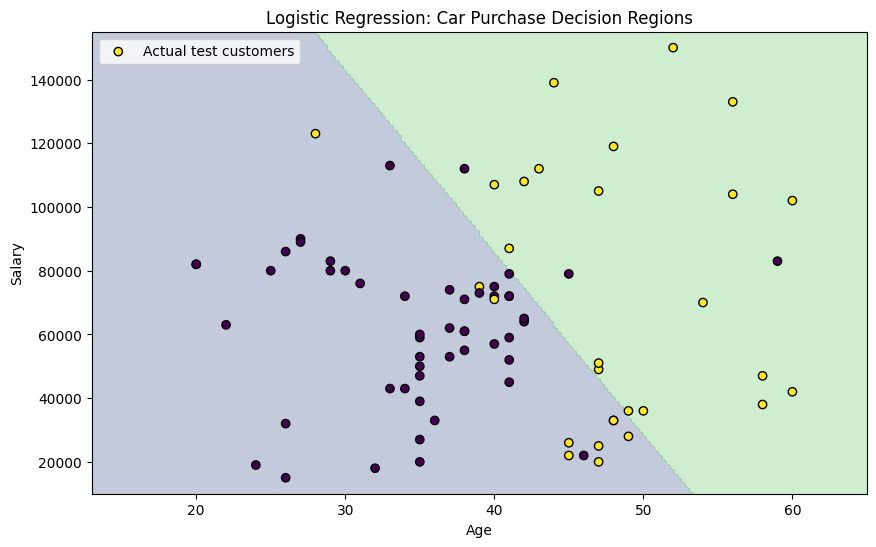

In [8]:
# Find the ranges of age and salary
age_min = X['Age'].min() - 5
age_max = X['Age'].max() + 5

salary_min = X['Salary'].min() - 5000
salary_max = X['Salary'].max() + 5000

# Create a grid of possible age and salary values
age_values = np.linspace(age_min, age_max, 200)
salary_values = np.linspace(salary_min, salary_max, 200)

age_grid, salary_grid = np.meshgrid(
    age_values, salary_values
)

# Put the grid values into a format the scaler expects
grid_data = pd.DataFrame({
    'Age': age_grid.ravel(),
    'Salary': salary_grid.ravel()
})

# Scale the grid and predict each point
grid_scaled = scaler.transform(grid_data)
predictions = model.predict(grid_scaled)

# Reshape predictions to match the grid
predictions = predictions.reshape(age_grid.shape)

# Draw the decision regions
plt.figure(figsize=(10, 6))

plt.contourf(
    age_grid,
    salary_grid,
    predictions,
    alpha=0.3,
    levels=[-0.5, 0.5, 1.5]
)

# Plot the actual test customers
plt.scatter(
    X_test['Age'],
    X_test['Salary'],
    c=y_test,
    edgecolors='black',
    label='Actual test customers'
)

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Logistic Regression: Car Purchase Decision Regions')
plt.legend()
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. Logistic regression outputs probabilities — why can it still be used for classification?

Logistic regression calculates the probability that an observation belongs to a particular class. Using a default threshold of 0.5, the model predicts class 1 when the probability is at least 0.5 and class 0 when it is below 0.5. Therefore, probabilities can be converted into categorical predictions.

2. Based on your model, which customers are more likely to purchase a car?

The model uses age and salary to estimate the likelihood of purchasing a car. Customers whose age and salary fall within the model's predicted purchase region are classified as more likely to purchase. The actual patterns should be interpreted using the decision-region graph and the model's learned coefficients.

3. What factors might cause low accuracy in this task?

Low accuracy may result from a small dataset, missing or incorrect values, overlapping patterns between customers who purchase and those who do not, or important features that are not included in the model. The train-test split can also affect the measured accuracy, especially when the dataset is small.

4. Propose additional features or preprocessing steps that could improve accuracy.

Additional features could include credit score, employment status, existing debt, car price, and previous purchase history, if these data are available and appropriate to use. Checking for missing values, correcting data errors, and evaluating different train-test splits or model settings may also help. Any changes should be evaluated on data that was not used to train the model.